In [91]:
import os
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import sys
sys.path.append(os.path.abspath(".."))   # one level up
import numpy as np
import cv2
import open3d as o3d
from scipy.spatial.transform import Rotation
from utils.lidar import PointCloud
from utils.camera import ImageData
import utils.utils as utils
from natsort import natsorted, index_natsorted
import torch
from tqdm import tqdm
import pickle

In [92]:

# Toggle the following boolean to False if not using HuggingFace App
hf_app = False

if hf_app:
    from huggingface_hub import snapshot_download

################## set device based on cuda availability #################
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

print('CUDA availability: ' + str(torch.cuda.is_available()))

####################### Functions for matching using numpy on CPU or Pytorch on GPU ###################
def getMatchIndsCPU(ft_ref,ft_qry,topK=20,metric='cosine'):
    """
    metric: 'euclidean' or 'cosine'
    """
    # dMat = cdist(ft_ref,ft_qry,metric)

    ft_qry_norm = ft_qry / np.linalg.norm(ft_qry, axis=1, keepdims=True)  # Shape (M, N)
    ft_ref_norm = ft_ref / np.linalg.norm(ft_ref, axis=1, keepdims=True)  # Shape (C, N)

    # Step 2: Compute cosine similarity
    dMat = 1 - (ft_ref_norm @ ft_qry_norm.T)
    mInds = np.argsort(dMat,axis=0)[:topK].squeeze() # shape: K x ft_qry.shape[0]
    return mInds, dMat


def getMatchIndsGPU(ft_ref, ft_qry,topK=20, metric='cosine'):
    # metric: 'euclidean' or 'cosine'
    ft_qry_tensor = torch.Tensor(ft_qry).to(device)
    ft_ref_tensor = torch.Tensor(ft_ref).to(device)

    if metric == 'euclidean':
        # Use torch's cdist for Euclidean distance
        dMat = torch.cdist(ft_ref, ft_qry)
    
    elif metric == 'cosine':
        # # Normalize both the query and reference tensors
        ft_qry_norm = ft_qry_tensor / ft_qry_tensor.norm(dim=1, keepdim=True)
        ft_ref_norm = ft_ref_tensor / ft_ref_tensor.norm(dim=1, keepdim=True)
        # Compute cosine similarity (1 - cosine similarity for distance)
        dMat = 1 - ft_ref_norm @ ft_qry_norm.t()

    # Get the indices of the top 5 closest matches
    mInds = torch.argsort(dMat, dim=0)[:topK].squeeze()
    
    return mInds, dMat

CUDA availability: True


In [93]:

qry_sets = [
    # 'Cambogan_20250811_113017',
    'DairyCreek_20250811_103318',
    # 'Holmview_20250820_130327',
    'Pullenvale_20250916_124105',
]

# qry_sets = [
#     'Cambogan_20250812_122101',
#     'Dairy-Creek_20250812_123312',
#     'Holmview_20250812_120856',
#     'Pullenvale_20250812_134524',
# ]

ref_sets = [
    # 'Cambogan_20250812_122339',
    'Dairy-Creek_20250812_122954',
    # 'Holmview_20250812_120100',
    'Pullenvale_20250812_134316',
]

vpr_descs = [
    'cosplace',
    'boq',
    'clique-mining',
    'cricavpr',
    'eigenplaces',
    'mixvpr',
    'salad',
    'supervlad',
    # 'anyloc-urban',
]

# vpr_descs = [
#     'cosplace',
# ]

img_calib_file = f"../camera_calib.txt"

dist_tolerances = [1, 2, 4, 6, 8, 10]
# dist_tolerance = 10 # metres
# qry_idx = 4

# User parameters

In [ ]:
recalls = {'Cambogan': {'cosplace': [], 'boq': [], 'clique-mining': [], 'cricavpr': [], 'eigenplaces': [], 'mixvpr': [], 'salad': [], 'supervlad': []},
           'DairyCreek': {'cosplace': [], 'boq': [], 'clique-mining': [], 'cricavpr': [], 'eigenplaces': [], 'mixvpr': [], 'salad': [], 'supervlad': []},
           'Holmview': {'cosplace': [], 'boq': [], 'clique-mining': [], 'cricavpr': [], 'eigenplaces': [], 'mixvpr': [], 'salad': [], 'supervlad': []},
           'Pullenvale': {'cosplace': [], 'boq': [], 'clique-mining': [], 'cricavpr': [], 'eigenplaces': [], 'mixvpr': [], 'salad': [], 'supervlad': []}
           }


for vpr_desc in vpr_descs:

    # print(f"Evaluating {vpr_desc} descriptors")

    # plt.figure()

    for qry_set in qry_sets:


        # print(f"Evaluating {qry_set}")

        ################ Query filenames and directories #################################
        qry_condition = 'flooded'
        # qry_condition = 'dry'
        qry_camera_pos = 'front'
        qry_root_directory = f"D:/Datasets/FRED/{qry_condition}/KITTI-style"
        qry_vpr_root = f"D:/Datasets/FRED/vpr_ftrs/{qry_condition}/KITTI-style"

        results_dir = f"{qry_vpr_root}/{qry_set}/{vpr_desc}/"
        
        with open(f"{results_dir}/in_tols.pkl", 'rb') as file:
            in_tols = pickle.load(file)
        with open(f"{results_dir}/distss.pkl", 'rb') as file:
            distss = pickle.load(file)
        with open(f"{results_dir}/valid_qrys.pkl", 'rb') as file:
            valid_qrys = pickle.load(file)

        for key in in_tols:
            # recalls.append(np.sum(np.array(in_tols[key]))/valid_qrys[key])
            recalls[qry_set.split('_')[0]][vpr_desc].append(np.sum(np.array(in_tols[key]))/valid_qrys[str(key)])

        print(f"Recall for {qry_set.split('_')[0]}, {vpr_desc}: {recalls[qry_set.split('_')[0]][vpr_desc][-1]}")
        print(f"valid_qrys for {qry_set.split('_')[0]}, {vpr_desc}: {valid_qrys[str('10')]}")
        print(f"in_tols for {qry_set.split('_')[0]}, {vpr_desc}: {np.array(in_tols[str('10')]).sum()}")

        # plt.plot(dist_tolerances, recalls, label=)

    # plt.tight_layout()
    # plt.title(f"{vpr_desc} Recall@1 plot")
    # plt.ylabel(f"Recall@1")
    # plt.xlabel(f"Distance Tolerance")
    # plt.legend()
    # plt.show()


Recall for DairyCreek, cosplace: 0.8392857142857143
valid_qrys for DairyCreek, cosplace: 280
in_tols for DairyCreek, cosplace: 235
Recall for Pullenvale, cosplace: 0.9498327759197325
valid_qrys for Pullenvale, cosplace: 299
in_tols for Pullenvale, cosplace: 284
Recall for DairyCreek, boq: 0.8428571428571429
valid_qrys for DairyCreek, boq: 280
in_tols for DairyCreek, boq: 236
Recall for Pullenvale, boq: 0.9866220735785953
valid_qrys for Pullenvale, boq: 299
in_tols for Pullenvale, boq: 295
Recall for DairyCreek, clique-mining: 0.8321428571428572
valid_qrys for DairyCreek, clique-mining: 280
in_tols for DairyCreek, clique-mining: 233
Recall for Pullenvale, clique-mining: 0.9966555183946488
valid_qrys for Pullenvale, clique-mining: 299
in_tols for Pullenvale, clique-mining: 298
Recall for DairyCreek, cricavpr: 0.725
valid_qrys for DairyCreek, cricavpr: 280
in_tols for DairyCreek, cricavpr: 203
Recall for Pullenvale, cricavpr: 1.0
valid_qrys for Pullenvale, cricavpr: 299
in_tols for Pullen

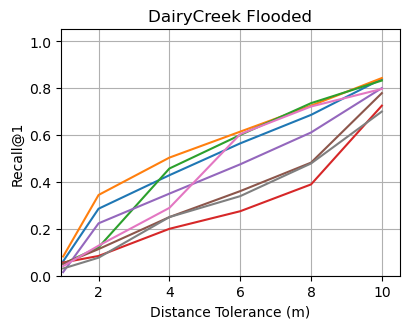

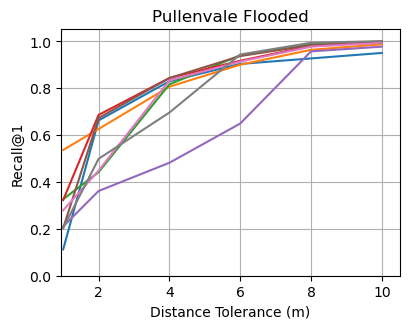

In [95]:
locations = ['DairyCreek', 'Pullenvale'] # ['Cambogan', 'DairyCreek', 'Holmview', 'Pullenvale'] # ['DairyCreek']

for location in locations:
    plt.figure(figsize=(4, 3))
    for key in recalls[location]:

        plt.plot(dist_tolerances, recalls[location][key], label=key)

    plt.tight_layout()
    plt.title(f"{location} Flooded")
    plt.ylabel(f"Recall@1")
    plt.ylim(0, 1.05)
    plt.xlim(0.95, 10.5)
    plt.xlabel(f"Distance Tolerance (m)")
    plt.grid('on')
    # plt.legend()
    # plt.savefig(f"{qry_vpr_root}/{location}_recall_sweep.pdf", dpi=300, format='PDF', bbox_inches='tight')
    plt.show()
    